In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
SEED = 42
sns.set_theme(style="whitegrid")
Path("../figures").mkdir(exist_ok=True)
df = pd.read_csv("../data/processed/ids_processed.csv")
CLASS_ORDER = ["Normal", "Brute-force", "DDoS"]

In [3]:
# Table 7: dimensions, labels, imbalance, cleaning log
print(df.shape)
print(df["Label_original"].value_counts())
print(df["Class"].value_counts(normalize=True).mul(100).round(2))
vc = df["Class"].value_counts()
print("Imbalance ratio (largest/smallest):", round(vc.max() / vc.min(), 1))
print(pd.read_csv("../data/processed/cleaning_log.csv"))

(1145322, 81)
Label_original
BENIGN         1008158
DDoS            128014
FTP-Patator       5931
SSH-Patator       3219
Name: count, dtype: int64
Class
Normal         88.02
DDoS           11.18
Brute-force     0.80
Name: proportion, dtype: float64
Imbalance ratio (largest/smallest): 110.2
                                   step     rows
0                       raw rows loaded  1201572
1  after removing missing/infinite rows  1200837
2         after removing duplicate rows  1145322


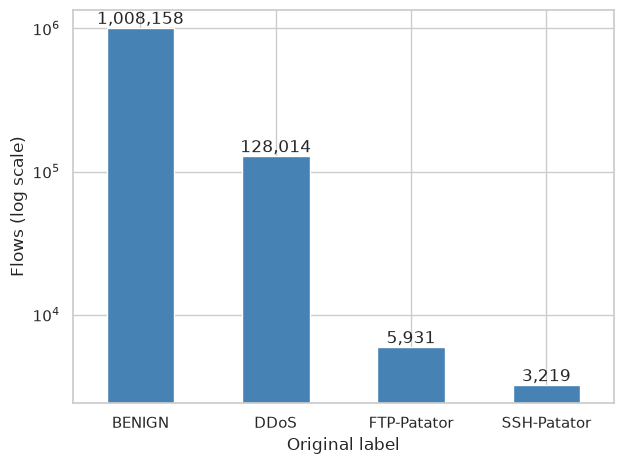

In [4]:
# Figure 2: class distribution (original labels, log scale)
counts = df["Label_original"].value_counts()
ax = counts.plot(kind="bar", logy=True, color="steelblue", rot=0)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
ax.set_xlabel("Original label"); ax.set_ylabel("Flows (log scale)")
plt.tight_layout(); plt.savefig("../figures/fig2_class_distribution.png", dpi=200); plt.show()

In [5]:
# Log columns used by Figures 3 and 4 (clip negative values at 0 first)
for col in ["Flow Duration", "Flow Packets/s", "Flow Bytes/s"]:
    df["log_" + col] = np.log10(df[col].clip(lower=0) + 1)

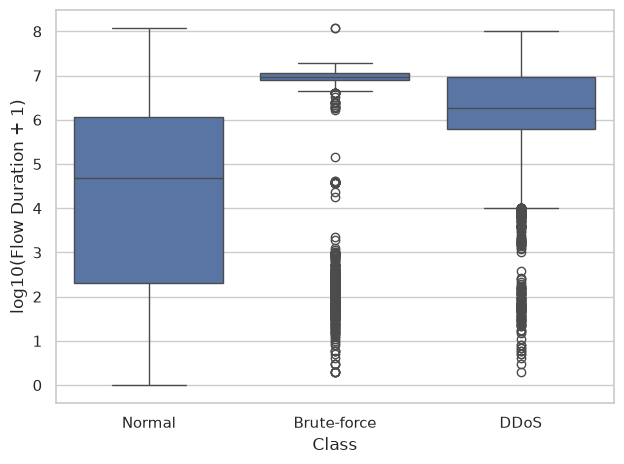

In [6]:
# Figure 3: flow duration by class
sns.boxplot(data=df, x="Class", y="log_Flow Duration", order=CLASS_ORDER)
plt.ylabel("log10(Flow Duration + 1)")
plt.tight_layout(); plt.savefig("../figures/fig3_duration.png", dpi=200); plt.show()

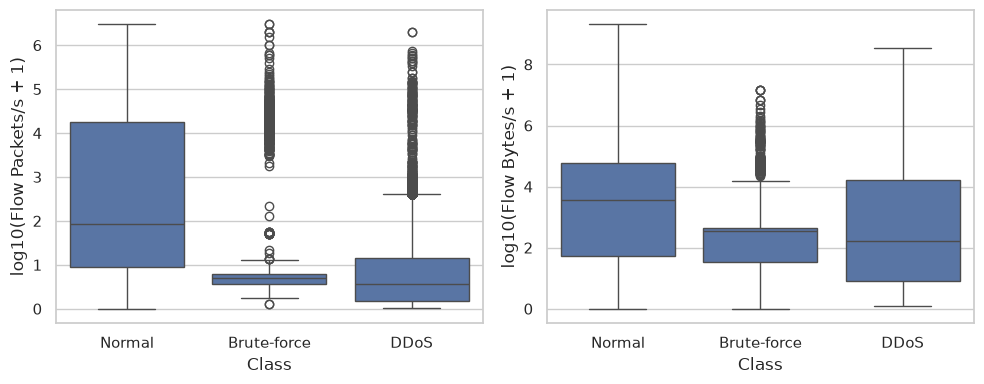

In [7]:
# Figure 4: packet rate and byte rate by class
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="Class", y="log_Flow Packets/s", order=CLASS_ORDER, ax=axes[0])
sns.boxplot(data=df, x="Class", y="log_Flow Bytes/s", order=CLASS_ORDER, ax=axes[1])
axes[0].set_ylabel("log10(Flow Packets/s + 1)"); axes[1].set_ylabel("log10(Flow Bytes/s + 1)")
plt.tight_layout(); plt.savefig("../figures/fig4_rates.png", dpi=200); plt.show()

In [8]:
# Top-5 destination ports per class (leakage-risk table)
for c in CLASS_ORDER:
    print(c, df.loc[df["Class"] == c, "Destination Port"]
          .value_counts(normalize=True).head(5).mul(100).round(1).to_dict())

Normal {53: 41.0, 443: 23.5, 80: 9.8, 123: 1.0, 22: 0.3}
Brute-force {21: 64.8, 22: 35.2, 80: 0.0}
DDoS {80: 100.0, 64869: 0.0, 64873: 0.0, 27636: 0.0}


In [9]:
# Correlated feature pairs above 0.95 (Table 7)
num = df.drop(columns=["row_id", "source_file", "Label_original", "Class"]
              + [c for c in df.columns if c.startswith("log_")])
corr = num.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().loc[lambda s: s > 0.95].sort_values(ascending=False)
print(len(pairs), "pairs above 0.95"); print(pairs.head(15))

34 pairs above 0.95
Total Backward Packets       Subflow Bwd Packets            1.000000
Total Fwd Packets            Subflow Fwd Packets            1.000000
Fwd PSH Flags                SYN Flag Count                 1.000000
Bwd Packet Length Mean       Avg Bwd Segment Size           1.000000
Fwd Packet Length Mean       Avg Fwd Segment Size           1.000000
Total Length of Fwd Packets  Subflow Fwd Bytes              1.000000
Total Length of Bwd Packets  Subflow Bwd Bytes              1.000000
Total Fwd Packets            Total Backward Packets         0.999293
                             Subflow Bwd Packets            0.999293
Total Backward Packets       Subflow Fwd Packets            0.999293
Subflow Fwd Packets          Subflow Bwd Packets            0.999293
Total Fwd Packets            Total Length of Bwd Packets    0.998623
Total Length of Bwd Packets  Subflow Fwd Packets            0.998623
Subflow Fwd Packets          Subflow Bwd Bytes              0.998619
Total Fwd Pack

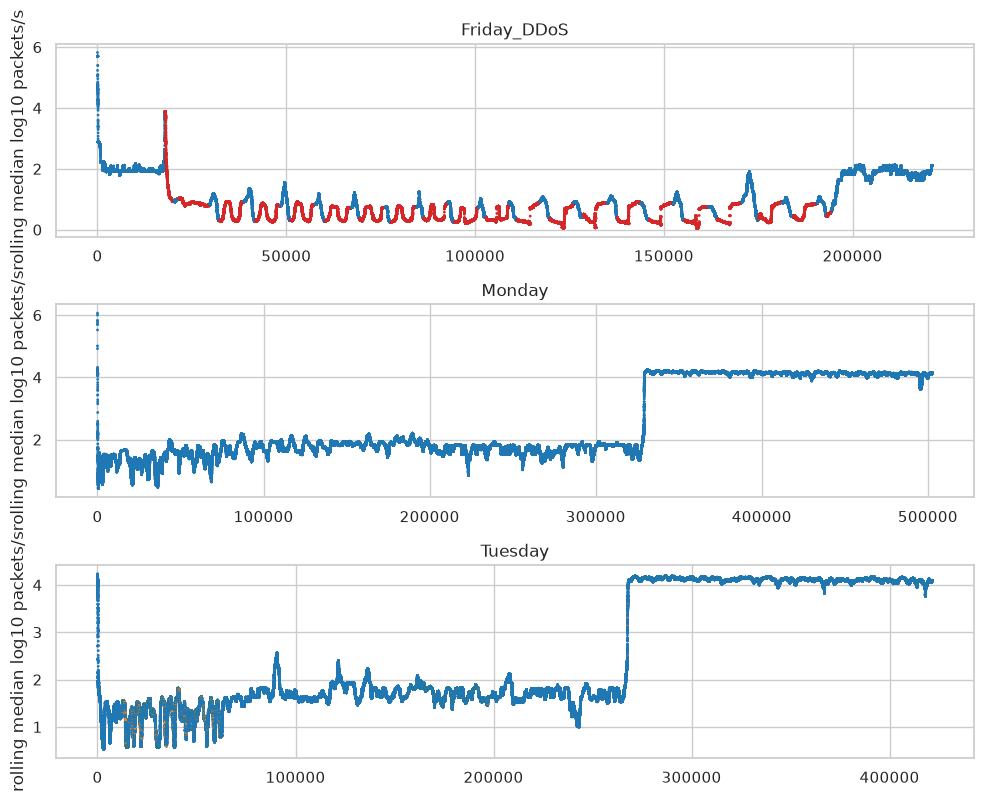

In [10]:
# Figure 5: spikes. Version A uses Timestamp if ids_meta.csv exists.
meta_path = Path("../data/processed/ids_meta.csv")
if meta_path.exists() and "Timestamp" in pd.read_csv(meta_path, nrows=1).columns:
    meta = pd.read_csv(meta_path, usecols=["row_id", "Timestamp"])
    t = df[["row_id", "Class", "source_file"]].merge(meta, on="row_id")
    t["Timestamp"] = pd.to_datetime(t["Timestamp"], errors="coerce")
    t["minute"] = t["Timestamp"].dt.floor("min")
    per_min = t.groupby(["source_file", "minute", "Class"]).size().reset_index(name="flows")
    g = sns.relplot(data=per_min, x="minute", y="flows", hue="Class", kind="line",
                    col="source_file", facet_kws={"sharex": False}, height=3.5)
    g.set(yscale="log"); g.set_xticklabels(rotation=45)
else:
    # Version B: rolling median packet rate in row order (no timestamps available)
    fig, axes = plt.subplots(3, 1, figsize=(10, 8))
    for ax, (name, part) in zip(axes, df.groupby("source_file")):
        roll = part["log_Flow Packets/s"].rolling(2000, min_periods=1).median()
        ax.scatter(range(len(part)), roll, s=1, c=part["Class"].map(
            {"Normal": "tab:blue", "Brute-force": "tab:orange", "DDoS": "tab:red"}))
        ax.set_title(name); ax.set_ylabel("rolling median log10 packets/s")
plt.tight_layout(); plt.savefig("../figures/fig5_spikes.png", dpi=200); plt.show()